In [1]:
import re
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
import rsatoolbox
import matplotlib.pyplot as plt
import json
from rsatoolbox.data.noise import prec_from_residuals

In [2]:
config = json.load(open("../../config.json"))

ROI_DIR = Path("../../masks_MNI152NLin2009cAsym")
FIRST_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/first_level_nipype")
SECOND_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/second_level_nipype")

OUT_DIR = Path(
    "../../results_added_residuals"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
ROI_COVERAGE_THRESHOLD = 0.80

# Lets not run a crossvalidated analysis with fewer than two independent runs
MIN_COMMON_RUNS = 2

# Exclude extremely tiny masks even if their proportional coverage is high.
MIN_VOXELS_ROI = 10

In [4]:
SESSION_MAP = {
    "b": "baseline",
    "f": "fasting",
    "s": "isolation",
}


# As from what I have googled, we should use cope when later doing multivariate
# noise normalization like Mahalanobis CV, othervise better to use 
# t-stats for Euclidean distances


STIMULI = {
    "food": "con_2_food_gt_rest_cope.nii.gz",
    "social": "con_4_social_gt_rest_cope.nii.gz",
    "flowers": "con_6_control_gt_rest_cope.nii.gz",
}

CONDITION_ORDER = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]

In [5]:
def split_subject_session(subject_session: str) -> tuple[str, str]:
    """
    SAXSISO01b -> ('SAXSISO01', 'b')
    """
    return subject_session[:-1], subject_session[-1]


def load_3d(path: Path) -> nib.Nifti1Image:
    img = nib.load(str(path))
    if img.ndim != 3:
        raise ValueError(f"Expected 3D image, found {img.ndim}D: {path}")
    return img


def same_grid(reference_img: nib.spatialimages.SpatialImage,
              test_img: nib.spatialimages.SpatialImage,
              atol: float = 1e-4) -> bool:
    return (
        reference_img.shape[:3] == test_img.shape[:3]
        and np.allclose(reference_img.affine, test_img.affine, atol=atol)
    )


def require_same_grid(reference_img, test_img, test_path: Path) -> None:
    if not same_grid(reference_img, test_img):
        raise ValueError(
            "\nGrid mismatch detected.\n"
            f"Reference shape: {reference_img.shape[:3]}\n"
            f"Test shape:      {test_img.shape[:3]}\n"
            f"Problem image:   {test_path}\n\n"
            "All cope maps, residuals, ROI masks, and run masks must be in "
            "the same MNI grid before extracting RSA patterns. Resample the "
            "data images with continuous interpolation and masks with nearest "
            "neighbor interpolation, then rerun."
        )


def get_mask_data(path: Path, reference_img: nib.Nifti1Image) -> np.ndarray:
    img = load_3d(path)
    require_same_grid(reference_img, img, path)
    return img.get_fdata() > 0


def run_dir_for(subject_session: str, run_label: str) -> Path:
    return FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model" /run_label


def available_run_labels(subject_session: str) -> list[str]:
    """
    Finds run1, run2, ... folders, retaining only folders with all three
    stimulus-vs-rest cope images.
    """
    cic_dir = FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model"

    if not cic_dir.exists():
        print(f"Directory does not exist: {cic_dir}")
        return []

    run_dirs = [
        p for p in cic_dir.iterdir()
        if p.is_dir() and re.fullmatch(r"run\d+", p.name)
    ]

    def run_number(path: Path) -> int:
        return int(re.search(r"\d+", path.name).group())

    run_dirs = sorted(run_dirs, key=run_number)

    complete_runs = []
    for run_dir in run_dirs:
        has_all_copes = all((run_dir / cope_name).exists()
                            for cope_name in STIMULI.values())
        if has_all_copes:
            complete_runs.append(run_dir.name)
        else:
            print(
                f"Skipping incomplete run: {run_dir}. "
                "At least one required cope is missing."
            )

    return complete_runs


def session_run_intersection_mask_path(subject_session: str) -> Path:
    """
    This is existing per-session intersection across that session's runs we saved after 1.5 level analysis.
    """
    folder = f"{subject_session}"
    return (
        SECOND_LEVEL_DIR
        / folder
        / "CIC"
        / "masks"
        / f"{folder}_CIC_run-intersection_mask.nii.gz"
    )


def build_joint_subject_mask(subject, roi_name):
    """
    ROI ∩ baseline run-intersection ∩ fasting run-intersection ∩ isolation run-intersection
    """
    session_masks = {}

    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        mask_path = session_run_intersection_mask_path(subject_session)

        if not mask_path.exists():
            raise FileNotFoundError(f"Missing run-intersection mask: {mask_path}")

        mask_img = load_3d(mask_path)
    
        session_masks[session_letter] = mask_img.get_fdata() > 0

    joint_run_mask = np.logical_and.reduce(list(session_masks.values()))

    roi_path = ROI_DIR / f"{roi_name}.gz"
    if not roi_path.exists():
        raise FileNotFoundError(f"ROI mask not found: {roi_path}")

    roi_mask = get_mask_data(roi_path, mask_img)
    if roi_mask.sum() == 0:
        raise ValueError(f"ROI is empty: {roi_name}")

    final_mask = roi_mask & joint_run_mask
    joint_coverage = final_mask.sum() / roi_mask.sum()

    return mask_img, final_mask, float(joint_coverage)


def get_common_runs(subject):
    runs_by_session = {}
    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        runs_by_session[session_letter] = set(available_run_labels(subject_session))

    common_runs = sorted(
        set.intersection(*runs_by_session.values()),
        key=lambda x: int(re.search(r"\d+", x).group()),
    )
    return common_runs

In [6]:
def load_subject_residuals(subject, reference_img, common_runs, cache_mask):
    """Load residuals once per run and session for the selected ROI voxels."""
    residuals = {}
    for run_label in common_runs:
        for session_letter in SESSION_MAP:
            run_dir = run_dir_for(f"{subject}{session_letter}", run_label)
            residual_path = run_dir / "res4d.nii.gz"
            img = nib.load(residual_path)
            if img.ndim != 4:
                raise ValueError(f"Expected 4D residuals: {residual_path}")
            require_same_grid(reference_img, img, residual_path)
            values = img.get_fdata(dtype=np.float32, caching="unchanged")[cache_mask].T
            if not np.all(np.isfinite(values)):
                raise ValueError(f"Non-finite residual values: {residual_path}")
            dof_path = run_dir / "dof"
            dof = float(dof_path.read_text().strip())
            if not np.isfinite(dof) or dof <= 0 or dof > values.shape[0]:
                raise ValueError(f"Invalid residual degrees of freedom in {dof_path}: {dof}")
            residuals[(run_label, session_letter)] = (values, dof)

    return {
        "subject": subject,
        "reference_img": reference_img,
        "mask": cache_mask,
        "runs": tuple(common_runs),
        "residuals": residuals,
    }


def extract_patterns_and_residuals(
    subject, analysis_mask, reference_img, common_runs, residual_cache=None, roi_name=None
):
    """Return run-by-condition patterns, their labels, and pooled precision."""
    if residual_cache is None:
        residual_cache = load_subject_residuals(
            subject, reference_img, common_runs, analysis_mask
        )
    if residual_cache["subject"] != subject or residual_cache["runs"] != tuple(common_runs):
        raise ValueError(f"Residual cache does not match subject/runs: {subject}")
    require_same_grid(reference_img, residual_cache["reference_img"], "residual cache")
    cache_mask = residual_cache["mask"]
    if np.any(analysis_mask & ~cache_mask):
        raise ValueError(f"ROI contains voxels outside the residual cache: {subject}, {roi_name}")
    roi_indices = analysis_mask[cache_mask]

    rows_measurements = []
    rows_condition = []
    rows_run = []

    residuals_list = []
    dof_list = []

    for run_label in common_runs:
        for session_letter, session_name in SESSION_MAP.items():
            subject_session = f"{subject}{session_letter}"
            run_dir = run_dir_for(subject_session, run_label)

            residuals, dof = residual_cache["residuals"][(run_label, session_letter)]
            residuals_list.append(residuals[:, roi_indices])
            dof_list.append(dof)

            for stimulus_name, cope_filename in STIMULI.items():
                cope_path = run_dir / cope_filename
                if not cope_path.exists():
                    raise FileNotFoundError(f"Missing cope: {cope_path}")

                cope_img = load_3d(cope_path)
                require_same_grid(reference_img, cope_img, cope_path)
                cope_values = cope_img.get_fdata(dtype=np.float32)[analysis_mask]

                if not np.all(np.isfinite(cope_values)):
                    raise ValueError(f"Non-finite cope values: {cope_path}")

                condition_name = f"{stimulus_name}_{session_name}"

                rows_measurements.append(cope_values)
                rows_condition.append(condition_name)
                rows_run.append(run_label)
                

    residuals_pooled = np.concatenate(residuals_list, axis=0)
    dof_pooled = sum(dof_list)
    precision = prec_from_residuals(residuals_pooled, dof=dof_pooled, method="shrinkage_diag")
    if not np.all(np.isfinite(precision)):
        raise ValueError(f"Non-finite precision matrix: subject={subject}, roi={roi_name}")

    measurements = np.stack(rows_measurements, axis=0)
    condition_labels = np.array(rows_condition)
    run_labels = np.array(rows_run)

    return measurements, condition_labels, run_labels, precision


In [7]:
subject = "sub-SAXSISO02" 
roi_name = "SNc_VTA.nii"

reference_img, analysis_mask, joint_coverage = build_joint_subject_mask(subject, roi_name)
n_voxels = int(analysis_mask.sum())

common_runs = get_common_runs(subject)

d = {
    "subject": subject,
    "roi": roi_name,
    "n_voxels": n_voxels,
    "joint_coverage": joint_coverage,
    "common_runs": common_runs,
}
print(d)


measurements, condition_labels, run_labels, precision = extract_patterns_and_residuals(
    subject, analysis_mask, reference_img, common_runs
)


dataset = rsatoolbox.data.Dataset(
    measurements=measurements,
    obs_descriptors={"condition": condition_labels, "run": run_labels},
)


rdm_obj = rsatoolbox.rdm.calc_rdm(
    dataset,
    method="crossnobis",
    descriptor="condition",
    cv_descriptor="run",
    noise=precision,
)

{'subject': 'sub-SAXSISO02', 'roi': 'SNc_VTA.nii', 'n_voxels': 21, 'joint_coverage': 1.0, 'common_runs': ['run1', 'run2', 'run3', 'run4', 'run5', 'run6']}


In [8]:
rdm_obj.dissimilarities

array([[ 0.01309239, -0.00609524, -0.00251244,  0.01259846, -0.00747687,
         0.02496766, -0.00828475,  0.00351003,  0.01555986,  0.01341073,
        -0.00053103,  0.02263529,  0.04120616, -0.00625871,  0.03914608,
         0.02683637,  0.0249983 ,  0.01029289,  0.04602885,  0.00931512,
         0.02838818,  0.01158111,  0.01001799,  0.00973435, -0.00357093,
         0.00449738,  0.01071979,  0.03199454,  0.00132522,  0.03099954,
         0.02024064,  0.00292225,  0.00219538,  0.01535842,  0.0124594 ,
         0.01331875]])

In [9]:
def compute_subject_roi_rdm(subject, roi_name, residual_cache=None):

    reference_img, analysis_mask, joint_coverage = build_joint_subject_mask(subject, roi_name)
    n_voxels = int(analysis_mask.sum())

    common_runs = get_common_runs(subject)

    if joint_coverage < ROI_COVERAGE_THRESHOLD or n_voxels < MIN_VOXELS_ROI or len(common_runs) < MIN_COMMON_RUNS:
        return None, {
            "subject": subject,
            "roi": roi_name,
            "included": False,
            "n_voxels": n_voxels,
            "joint_coverage": joint_coverage,
            "common_runs": common_runs,
        }


    measurements, condition_labels, run_labels, precision = extract_patterns_and_residuals(
        subject, analysis_mask, reference_img, common_runs, residual_cache, roi_name
    )

    dataset = rsatoolbox.data.Dataset(
        measurements=measurements,
        obs_descriptors={"condition": condition_labels, "run": run_labels},
    )

    rdm_obj = rsatoolbox.rdm.calc_rdm(
        dataset,
        method="crossnobis",
        descriptor="condition",
        cv_descriptor="run",
        noise=precision,
    )

    # Reorder to CONDITION_ORDER (calc_rdm sorts labels
    # alphabetically by default, not in intended order)
    rdm_obj.reorder(np.array([
        list(rdm_obj.pattern_descriptors["condition"]).index(c)
        for c in CONDITION_ORDER
    ]))

    rdm_matrix = rdm_obj.get_matrices()[0]
    if not np.all(np.isfinite(rdm_matrix)):
        raise ValueError(f"Non-finite RDM: subject={subject}, roi={roi_name}")

    dict_row = {
        "subject": subject,
        "roi": roi_name,
        "included": True,
        "n_voxels": n_voxels,
        "joint_coverage": joint_coverage,
        "common_runs": common_runs,
    }
    return rdm_matrix, dict_row


In [10]:
roi_names = [f.stem for f in ROI_DIR.glob("*.nii.gz")]

# we exclude roi where because of coverage threshold too little participants
# or roi that are aggregation of other included roi
# Also roi that intersect across alases (Ca/Caudate, Pu/Putamen, NAC/Accumbens, GPe and GPI with Pallidum)
rois_to_exnclude = ['Inferior Temporal Gyrus, anterior division.nii',
 'Inferior Temporal Gyrus, posterior division.nii',
 'Parahippocampal Gyrus, anterior division.nii',
 'Temporal Fusiform Cortex, posterior division.nii',
 'Temporal Pole.nii',
 'Cerebral Cortex.nii',
 'Cerebral White Matter.nii',
 'Lateral Ventricle.nii',
 'Brain-Stem.nii',
 'Caudate.nii',
 'Putamen.nii',
 'Accumbens.nii',
 'Pallidum.nii']
roi_names = [roi for roi in roi_names if roi not in rois_to_exnclude]
roi_names

['Subcallosal Cortex.nii',
 'SNc_VTA.nii',
 'Cingulate Gyrus, anterior division.nii',
 'Superior Frontal Gyrus.nii',
 'Temporal Fusiform Cortex, anterior division.nii',
 'HN.nii',
 'Superior Parietal Lobule.nii',
 'Insular Cortex.nii',
 'SNr.nii',
 'EXA.nii',
 'Parahippocampal Gyrus, posterior division.nii',
 'Amygdala.nii',
 'Cuneal Cortex.nii',
 'Supracalcarine Cortex.nii',
 'Middle Frontal Gyrus.nii',
 'Paracingulate Gyrus.nii',
 'Hippocampus.nii',
 'Inferior Frontal Gyrus, pars opercularis.nii',
 'Middle Temporal Gyrus, posterior division.nii',
 'Cingulate Gyrus, posterior division.nii',
 'Postcentral Gyrus.nii',
 'Intracalcarine Cortex.nii',
 'Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex).nii',
 'Temporal Occipital Fusiform Cortex.nii',
 'Frontal Orbital Cortex.nii',
 'Occipital Fusiform Gyrus.nii',
 'Inferior Temporal Gyrus, temporooccipital part.nii',
 'Planum Temporale.nii',
 'Pu.nii',
 'Parietal Opercular Cortex.nii',
 'Frontal Pole.nii',
 'Supramarginal 

In [11]:
len(roi_names)
# We use 3 atlases so some of the regions may overlap or be duplicated across atlases

61

In [12]:
subjects = sorted(set(f.stem[:-1] for f in Path(FIRST_LEVEL_DIR).glob("sub-*")))
subjects

['sub-SAXSISO01',
 'sub-SAXSISO02',
 'sub-SAXSISO03',
 'sub-SAXSISO04',
 'sub-SAXSISO08',
 'sub-SAXSISO09',
 'sub-SAXSISO10',
 'sub-SAXSISO11',
 'sub-SAXSISO12',
 'sub-SAXSISO13',
 'sub-SAXSISO14',
 'sub-SAXSISO15',
 'sub-SAXSISO17',
 'sub-SAXSISO18',
 'sub-SAXSISO19',
 'sub-SAXSISO21',
 'sub-SAXSISO22',
 'sub-SAXSISO24',
 'sub-SAXSISO26',
 'sub-SAXSISO27',
 'sub-SAXSISO28',
 'sub-SAXSISO30',
 'sub-SAXSISO32',
 'sub-SAXSISO33',
 'sub-SAXSISO34',
 'sub-SAXSISO35',
 'sub-SAXSISO36',
 'sub-SAXSISO38',
 'sub-SAXSISO39',
 'sub-SAXSISO40',
 'sub-SAXSISO41',
 'sub-SAXSISO42']

In [13]:
len(subjects)

32

In [14]:
rdm, row = compute_subject_roi_rdm("sub-SAXSISO01", "Occipital Pole.nii")
print(row["included"], row["n_voxels"], row["joint_coverage"])
print(None if rdm is None else (np.isnan(rdm).any(), np.diag(rdm)[:3]))

True 1398 0.9407806191117093
(np.False_, array([0., 0., 0.]))


In [15]:
rdm

array([[ 0.        ,  0.06279271, -0.00587918,  0.19663036,  0.22736009,
         0.19101561,  0.32408885,  0.36979576,  0.31683256],
       [ 0.06279271,  0.        ,  0.05080524,  0.24892742,  0.16596027,
         0.2145945 ,  0.35194592,  0.33824647,  0.33436352],
       [-0.00587918,  0.05080524,  0.        ,  0.19246883,  0.20787736,
         0.18139195,  0.32562636,  0.35868108,  0.30788027],
       [ 0.19663036,  0.24892742,  0.19246883,  0.        ,  0.06663354,
         0.01482184,  0.39811479,  0.45442166,  0.40304241],
       [ 0.22736009,  0.16596027,  0.20787736,  0.06663354,  0.        ,
         0.05100943,  0.42160377,  0.40496713,  0.41001783],
       [ 0.19101561,  0.2145945 ,  0.18139195,  0.01482184,  0.05100943,
         0.        ,  0.38787444,  0.44597112,  0.39198679],
       [ 0.32408885,  0.35194592,  0.32562636,  0.39811479,  0.42160377,
         0.38787444,  0.        ,  0.08974181,  0.00939146],
       [ 0.36979576,  0.33824647,  0.35868108,  0.45442166,  0

In [16]:
import warnings
from importlib.metadata import version

if not subjects or not roi_names:
    raise ValueError("No subjects or ROI masks found.")
if len(set(subjects)) != len(subjects) or len(set(roi_names)) != len(roi_names):
    raise ValueError("Subject and ROI names must be unique.")

n_sub, n_roi, n = len(subjects), len(roi_names), len(CONDITION_ORDER)
rdms = np.full((n_sub, n_roi, n, n), np.nan)
rows = []
completed_subjects = set()
rdm_path = OUT_DIR / "crossnobis_rdms.npz"
metadata_path = OUT_DIR / "rdm_metadata.csv"
analysis_settings = {
    "roi_coverage_threshold": ROI_COVERAGE_THRESHOLD,
    "min_common_runs": MIN_COMMON_RUNS,
    "min_voxels_roi": MIN_VOXELS_ROI,
    "session_map": SESSION_MAP,
    "stimuli": STIMULI,
    "roi_dir": str(ROI_DIR.resolve()),
    "first_level_dir": str(FIRST_LEVEL_DIR.resolve()),
    "second_level_dir": str(SECOND_LEVEL_DIR.resolve()),
    "distance": "crossnobis",
    "precision_method": "shrinkage_diag",
    "rsatoolbox_version": version("rsatoolbox"),
}

if rdm_path.exists() != metadata_path.exists():
    raise FileNotFoundError("Resume requires both crossnobis_rdms.npz and rdm_metadata.csv.")

if rdm_path.exists():
    metadata = pd.read_csv(metadata_path, dtype={"included": "boolean"})
    required_columns = {"subject", "roi", "included", "n_voxels", "joint_coverage", "common_runs"}
    if not required_columns.issubset(metadata.columns):
        raise ValueError("Checkpoint metadata is missing required columns.")
    if metadata[["subject", "roi", "included"]].isna().any().any():
        raise ValueError("Checkpoint metadata has missing subject, ROI, or inclusion values.")
    if metadata.duplicated(["subject", "roi"]).any():
        raise ValueError("Checkpoint metadata has duplicate subject/ROI rows.")
    if not metadata["subject"].isin(subjects).all() or not metadata["roi"].isin(roi_names).all():
        raise ValueError("Checkpoint metadata contains unknown subjects or ROIs.")

    with np.load(rdm_path, allow_pickle=False) as checkpoint:
        saved_subjects = checkpoint["subjects"].tolist()
        saved_rois = checkpoint["rois"].tolist()
        saved_conditions = checkpoint["conditions"].tolist()
        if (len(saved_subjects) != n_sub or set(saved_subjects) != set(subjects)
                or len(saved_rois) != n_roi or set(saved_rois) != set(roi_names)
                or saved_conditions != list(CONDITION_ORDER)):
            raise ValueError("Checkpoint subjects, ROIs, or condition order do not match this analysis.")
        if "analysis_settings" in checkpoint:
            if json.loads(checkpoint["analysis_settings"].item()) != analysis_settings:
                raise ValueError("Checkpoint analysis settings do not match this analysis.")
        else:
            warnings.warn("Checkpoint has no saved analysis settings; verify they match before resuming.")
        saved_rdms = checkpoint["rdms"]
        if saved_rdms.shape != (n_sub, n_roi, n, n):
            raise ValueError("Checkpoint RDM array has an unexpected shape.")
        subject_indices = [saved_subjects.index(subject) for subject in subjects]
        roi_indices = [saved_rois.index(roi) for roi in roi_names]
        rdms = saved_rdms[subject_indices][:, roi_indices, :, :]

    for i, subject in enumerate(subjects):
        subject_rows = metadata.loc[metadata["subject"] == subject]
        if len(subject_rows) != n_roi:
            if not subject_rows.empty:
                print(f"Incomplete checkpoint for {subject}; recomputing that participant.")
            rdms[i] = np.nan
            continue
        for row in subject_rows.itertuples(index=False):
            matrix = rdms[i, roi_names.index(row.roi)]
            if row.included and not np.isfinite(matrix).all():
                raise ValueError(f"Checkpoint has a non-finite RDM: {subject}, {row.roi}")
            if not row.included and not np.isnan(matrix).all():
                raise ValueError(f"Checkpoint has an RDM for an excluded ROI: {subject}, {row.roi}")
        completed_subjects.add(subject)

    rows = metadata.loc[metadata["subject"].isin(completed_subjects)].to_dict("records")
    print(f"Resuming: {len(completed_subjects)} of {n_sub} participants already complete.")

df = pd.DataFrame(rows)
if len(completed_subjects) < n_sub:
    reference_path = session_run_intersection_mask_path(f"{subjects[0]}{next(iter(SESSION_MAP))}")
    cache_reference = load_3d(reference_path)
    cache_mask = np.zeros(cache_reference.shape, dtype=bool)
    for roi_name in roi_names:
        cache_mask |= get_mask_data(ROI_DIR / f"{roi_name}.gz", cache_reference)

for i, subject in enumerate(subjects):
    if subject in completed_subjects:
        print(f"Skipping completed participant: {subject}")
        continue
    subject_cache_mask = cache_mask.copy()
    for session_letter in SESSION_MAP:
        mask_path = session_run_intersection_mask_path(f"{subject}{session_letter}")
        session_mask = load_3d(mask_path)
        require_same_grid(cache_reference, session_mask, mask_path)
        subject_cache_mask &= session_mask.get_fdata() > 0

    common_runs = get_common_runs(subject)
    residual_cache = None
    if len(common_runs) >= MIN_COMMON_RUNS:
        residual_cache = load_subject_residuals(subject, cache_reference, common_runs, subject_cache_mask)

    for j, roi_name in enumerate(roi_names):
        print(f"Processing subject={subject}, roi={roi_name}")
        rdm, dict_row = compute_subject_roi_rdm(subject, roi_name, residual_cache)
        if rdm is not None:
            rdms[i, j] = rdm
        rows.append(dict_row)

    del residual_cache
    df = pd.DataFrame(rows)
    rdm_tmp = OUT_DIR / ".crossnobis_rdms.tmp.npz"
    metadata_tmp = OUT_DIR / ".rdm_metadata.tmp.csv"
    np.savez_compressed(
        rdm_tmp,
        rdms=rdms,
        subjects=np.array(subjects),
        rois=np.array(roi_names),
        conditions=np.array(CONDITION_ORDER),
        analysis_settings=json.dumps(analysis_settings, sort_keys=True),
    )
    df.to_csv(metadata_tmp, index=False)
    rdm_tmp.replace(rdm_path)
    metadata_tmp.replace(metadata_path)
    print(f"Saved checkpoint after {subject} ({i + 1}/{n_sub} participants)")


Processing subject=sub-SAXSISO01, roi=Subcallosal Cortex.nii


/Users/anna/Desktop/anpa/.venv313/lib/python3.13/site-packages/rsatoolbox/data/computations.py:36: RuntimeWarning: invalid value encountered in multiply
  average = np.nan * np.empty(


Processing subject=sub-SAXSISO01, roi=SNc_VTA.nii
Processing subject=sub-SAXSISO01, roi=Cingulate Gyrus, anterior division.nii
Processing subject=sub-SAXSISO01, roi=Superior Frontal Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Temporal Fusiform Cortex, anterior division.nii
Processing subject=sub-SAXSISO01, roi=HN.nii
Processing subject=sub-SAXSISO01, roi=Superior Parietal Lobule.nii
Processing subject=sub-SAXSISO01, roi=Insular Cortex.nii
Processing subject=sub-SAXSISO01, roi=SNr.nii
Processing subject=sub-SAXSISO01, roi=EXA.nii
Processing subject=sub-SAXSISO01, roi=Parahippocampal Gyrus, posterior division.nii
Processing subject=sub-SAXSISO01, roi=Amygdala.nii
Processing subject=sub-SAXSISO01, roi=Cuneal Cortex.nii
Processing subject=sub-SAXSISO01, roi=Supracalcarine Cortex.nii
Processing subject=sub-SAXSISO01, roi=Middle Frontal Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Paracingulate Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Hippocampus.nii
Processing subject=sub-SAXS

In [17]:
roi = nib.load('/Users/anna/Desktop/anpa/probing_rsa_fasting_social_isolation/masks/Superior Temporal Gyrus, posterior division.nii.gz')
roi.get_fdata().any()

np.True_

In [18]:
roi.get_fdata().any()

np.True_

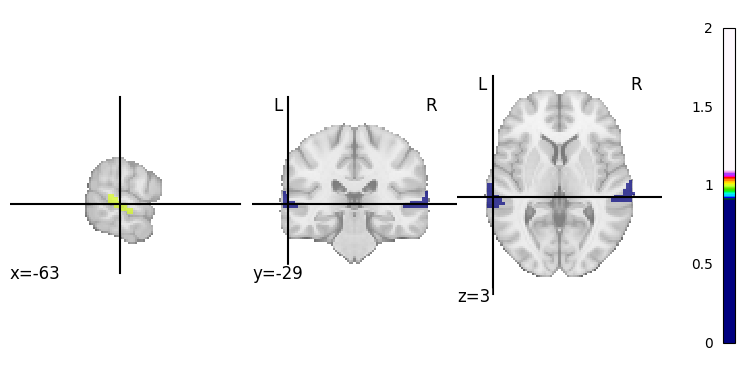

In [19]:
from nilearn.plotting import plot_roi
plot_roi('/Users/anna/Desktop/anpa/probing_rsa_fasting_social_isolation/masks_MNI152NLin2009cAsym/Superior Temporal Gyrus, posterior division.nii.gz')

In [20]:
rdms.shape

(32, 61, 9, 9)

In [21]:
df

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Subcallosal Cortex.nii,True,305,0.932722,"[run1, run2, run5, run6]"
1,sub-SAXSISO01,SNc_VTA.nii,True,21,1.000000,"[run1, run2, run5, run6]"
2,sub-SAXSISO01,"Cingulate Gyrus, anterior division.nii",True,724,1.000000,"[run1, run2, run5, run6]"
3,sub-SAXSISO01,Superior Frontal Gyrus.nii,True,1657,0.980473,"[run1, run2, run5, run6]"
4,sub-SAXSISO01,"Temporal Fusiform Cortex, anterior division.nii",False,29,0.177914,"[run1, run2, run5, run6]"
...,...,...,...,...,...,...
1947,sub-SAXSISO42,"Lateral Occipital Cortex, superior division.nii",True,2658,0.994760,"[run1, run2, run3, run4, run5, run6]"
1948,sub-SAXSISO42,"Superior Temporal Gyrus, anterior division.nii",True,165,1.000000,"[run1, run2, run3, run4, run5, run6]"
1949,sub-SAXSISO42,"Middle Temporal Gyrus, temporooccipital part.nii",True,587,0.989882,"[run1, run2, run3, run4, run5, run6]"
1950,sub-SAXSISO42,"Middle Temporal Gyrus, anterior division.nii",True,228,0.923077,"[run1, run2, run3, run4, run5, run6]"


In [22]:
df.query('included == False').roi.value_counts()

roi
Temporal Fusiform Cortex, anterior division.nii       32
HN.nii                                                32
Subcallosal Cortex.nii                                11
Frontal Orbital Cortex.nii                             7
SNr.nii                                                5
SNc_VTA.nii                                            4
PBP.nii                                                4
MN.nii                                                 2
RN.nii                                                 2
Inferior Temporal Gyrus, temporooccipital part.nii     1
Amygdala.nii                                           1
Hippocampus.nii                                        1
Frontal Pole.nii                                       1
HTH.nii                                                1
Occipital Pole.nii                                     1
Name: count, dtype: int64

In [23]:
df.query('included')

,subject,roi,included,n_voxels,joint_coverage,common_runs
0,sub-SAXSISO01,Subcallosal Cortex.nii,True,305,0.932722,"[run1, run2, run5, run6]"
1,sub-SAXSISO01,SNc_VTA.nii,True,21,1.000000,"[run1, run2, run5, run6]"
2,sub-SAXSISO01,"Cingulate Gyrus, anterior division.nii",True,724,1.000000,"[run1, run2, run5, run6]"
3,sub-SAXSISO01,Superior Frontal Gyrus.nii,True,1657,0.980473,"[run1, run2, run5, run6]"
6,sub-SAXSISO01,Superior Parietal Lobule.nii,True,920,0.998914,"[run1, run2, run5, run6]"
...,...,...,...,...,...,...
1947,sub-SAXSISO42,"Lateral Occipital Cortex, superior division.nii",True,2658,0.994760,"[run1, run2, run3, run4, run5, run6]"
1948,sub-SAXSISO42,"Superior Temporal Gyrus, anterior division.nii",True,165,1.000000,"[run1, run2, run3, run4, run5, run6]"
1949,sub-SAXSISO42,"Middle Temporal Gyrus, temporooccipital part.nii",True,587,0.989882,"[run1, run2, run3, run4, run5, run6]"
1950,sub-SAXSISO42,"Middle Temporal Gyrus, anterior division.nii",True,228,0.923077,"[run1, run2, run3, run4, run5, run6]"


In [24]:
df.query('included').roi.value_counts()

roi
Lateral Occipital Cortex, superior division.nii                            32
Supramarginal Gyrus, anterior division.nii                                 32
Pu.nii                                                                     32
Parietal Opercular Cortex.nii                                              32
Superior Temporal Gyrus, anterior division.nii                             32
Supramarginal Gyrus, posterior division.nii                                32
Middle Temporal Gyrus, temporooccipital part.nii                           32
GPi.nii                                                                    32
Precentral Gyrus.nii                                                       32
Inferior Frontal Gyrus, pars triangularis.nii                              32
VeP.nii                                                                    32
STH.nii                                                                    32
NAC.nii                                                     

In [25]:
len(df.query('included').roi.value_counts())

59

In [26]:
d = np.load(OUT_DIR / "crossnobis_rdms.npz")
d

NpzFile '../../results_added_residuals/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions, analysis_settings

In [27]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Pu.nii")]
rdm

array([[ 0.        , -0.00028014, -0.00137852,  0.0003345 , -0.0003829 ,
         0.00519089,  0.01074568,  0.00840001,  0.0101301 ],
       [-0.00028014,  0.        ,  0.00477721,  0.00597187, -0.00256995,
        -0.0018298 ,  0.0057879 ,  0.00800014,  0.00974407],
       [-0.00137852,  0.00477721,  0.        ,  0.00627115,  0.00017662,
         0.0019571 ,  0.0122206 ,  0.00954974,  0.01128116],
       [ 0.0003345 ,  0.00597187,  0.00627115,  0.        ,  0.00824318,
         0.00632083,  0.00823496,  0.00836882,  0.01382787],
       [-0.0003829 , -0.00256995,  0.00017662,  0.00824318,  0.        ,
        -0.00071861,  0.00928361,  0.01051199,  0.01333746],
       [ 0.00519089, -0.0018298 ,  0.0019571 ,  0.00632083, -0.00071861,
         0.        ,  0.00431983,  0.00462567,  0.00474067],
       [ 0.01074568,  0.0057879 ,  0.0122206 ,  0.00823496,  0.00928361,
         0.00431983,  0.        ,  0.00451408, -0.00056179],
       [ 0.00840001,  0.00800014,  0.00954974,  0.00836882,  0

In [28]:
def plot_rdm(rdm_matrix, subject, roi_name):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(rdm_matrix, cmap="viridis")
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_yticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=90)
    ax.set_yticklabels(CONDITION_ORDER)
    ax.set_title(f"sub-{subject} | {roi_name}")
    fig.colorbar(im, ax=ax, label="crossnobis distance")
    fig.tight_layout()

    plt.show()
    plt.close(fig)

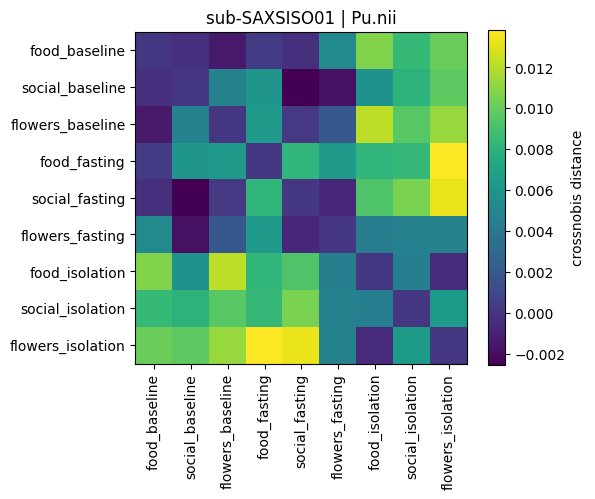

ValueError: 'Putamen.nii' is not in list

In [29]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Pu.nii")]
plot_rdm(rdm, "SAXSISO01", "Pu.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Putamen.nii")]
plot_rdm(rdm, "SAXSISO01", "Putamen.nii")
# Different atlases (could be different roi borders). I checked different subjects and the pattern holds

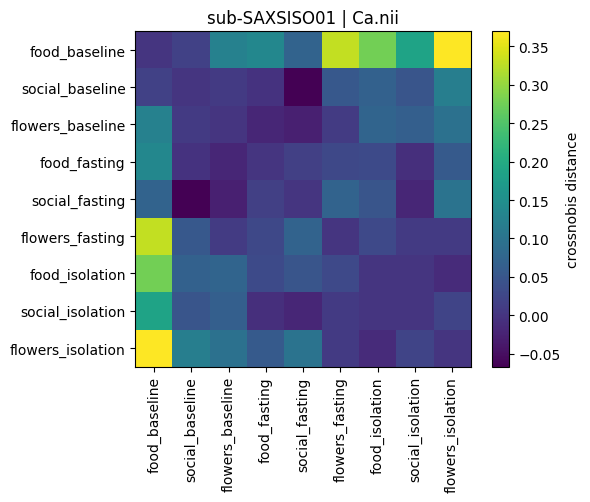

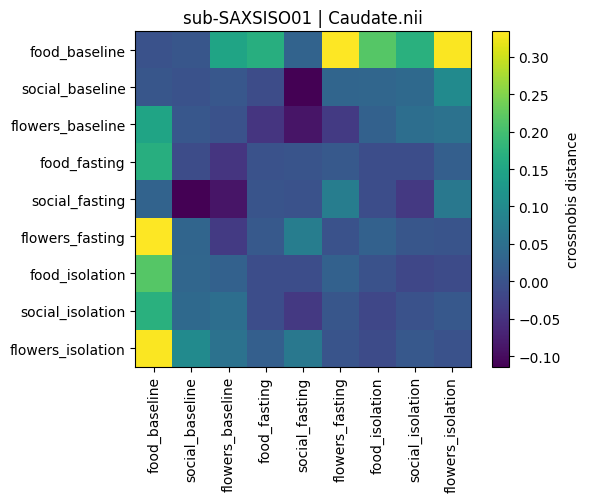

In [ ]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Ca.nii")]
plot_rdm(rdm, "SAXSISO01", "Ca.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Caudate.nii")]
plot_rdm(rdm, "SAXSISO01", "Caudate.nii")
# Different atlases (could be different roi borders). I checked different subjects and the pattern holds

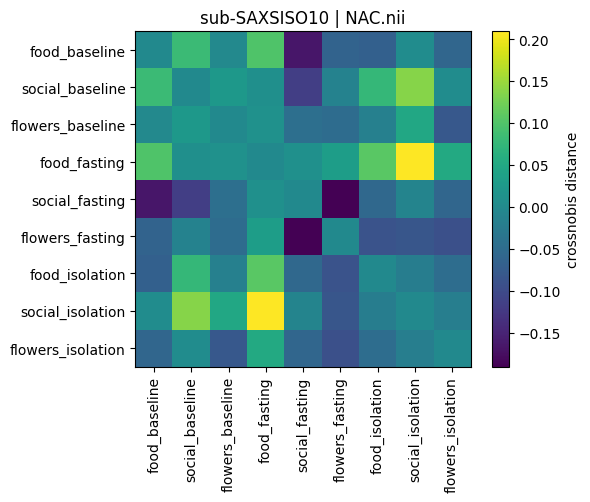

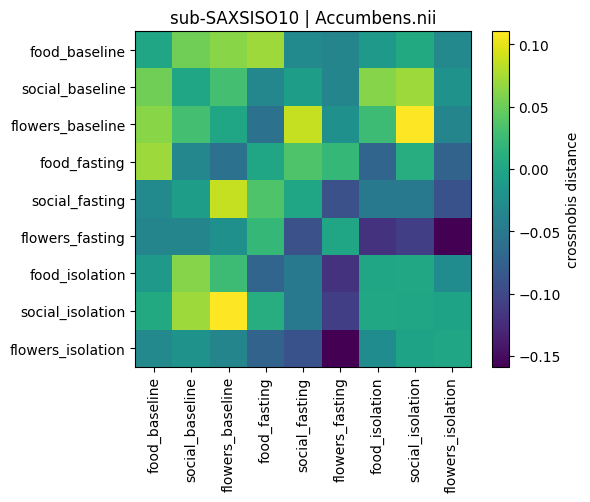

In [ ]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO10"), list(d["rois"]).index("NAC.nii")]
plot_rdm(rdm, "SAXSISO10", "NAC.nii")

rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO10"), list(d["rois"]).index("Accumbens.nii")]
plot_rdm(rdm, "SAXSISO10", "Accumbens.nii")
# In this ROI pattern does not seem to hold as clearly as in other ROIs
# Lets just leave all roi, and group them ba atlas for further analysis, for example do fdr correction within atlas

In [ ]:
d = np.load(OUT_DIR / "crossnobis_rdms.npz")
meta = pd.read_csv(OUT_DIR / "rdm_metadata.csv")
subjects, rois = list(d["subjects"]), list(d["rois"])
bad = [(r.subject, r.roi) for r in meta.query("included").itertuples()
       if np.isnan(d["rdms"][subjects.index(r.subject), rois.index(r.roi)]).all()]
len(bad)

0

In [ ]:
d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Occipital Pole.nii")]

array([[ 0.        ,  0.63181707, -0.30320243,  0.54263105,  1.28679627,
         0.2668307 ,  1.61585324,  3.6706205 ,  1.48371175],
       [ 0.63181707,  0.        ,  1.8642258 ,  4.08770271,  2.38211051,
         2.51239393,  2.79816117,  5.92576565,  3.71755594],
       [-0.30320243,  1.8642258 ,  0.        ,  1.00470687,  1.56329361,
         0.99635157,  2.44266994,  3.68757592,  2.0226131 ],
       [ 0.54263105,  4.08770271,  1.00470687,  0.        ,  0.73682319,
         0.14083035,  3.52221329,  4.41761491,  3.07873706],
       [ 1.28679627,  2.38211051,  1.56329361,  0.73682319,  0.        ,
         0.38841131,  3.52682241,  3.96822795,  3.38479975],
       [ 0.2668307 ,  2.51239393,  0.99635157,  0.14083035,  0.38841131,
         0.        ,  3.04524302,  4.83920104,  3.05568423],
       [ 1.61585324,  2.79816117,  2.44266994,  3.52221329,  3.52682241,
         3.04524302,  0.        ,  1.63984914,  0.14741004],
       [ 3.6706205 ,  5.92576565,  3.68757592,  4.41761491,  3